# Detección de anomalías en el valor del suelo

El notebook de clusters marcó 488 manzanas raras **a escala de ciudad**. Este va
tras dos rarezas distintas, que ese enfoque no puede ver:

| | La pregunta | Ejemplo |
|---|---|---|
| **Espacial** | ¿es rara **para su vecindario**? | una manzana a 900 k rodeada de manzanas a 4 M |
| **Temporal** | ¿en **qué año** se rompió su serie? | "esta manzana se disparó en 2024" |

La diferencia con el enfoque global importa: una manzana de 900 k es
perfectísimamente normal en Bogotá —hay miles— y puede ser, al mismo tiempo, la
más anómala de su cuadra. Un detector que mire la distribución de toda la ciudad
nunca la va a encontrar. Y marcar "esta manzana es rara" sirve mucho menos que
decir en qué año y en qué dirección se rompió.

## Cómo se ataca

**Anomalía espacial.** El truco está en la *representación*, no en el
algoritmo: en vez de dar a los detectores el vector de comportamiento de la
manzana, se les da el **residuo frente a lo que hacen sus vecinos**. Con esa
transformación, "raro para su contexto" se convierte en "raro", y cualquier
detector estándar sirve. Se comparan siete.

**Anomalía temporal.** La unidad de análisis deja de ser la manzana y pasa a ser
la **transición** (manzana, año): 9 por manzana, unas 337 mil en total. Cada una
se describe por su crecimiento, el de la ciudad ese año, el de sus vecinos y su
propio pasado. Después se busca el año de quiebre de cada serie y se clasifica
qué tipo de ruptura fue.

## El problema de fondo: no hay etiquetas

Nadie marcó cuáles manzanas son "realmente" anómalas, así que no se puede medir
acierto de la manera habitual. La salida de esto es **inyectar anomalías
sintéticas** —construidas a propósito, de magnitud conocida— y medir qué
fracción recupera cada detector. Es lo que convierte la comparación entre
métodos en algo verificable en vez de una cuestión de gusto.

## Qué entrega

Una **lista priorizada** de manzanas y transiciones, cada una con el detector
que la marcó, la variable que la delató, el año del quiebre, y una
clasificación en dos cubetas que es la distinción que de verdad importa:

> **artefacto administrativo** (Catastro revaluó la zona entera) **vs. posible
> señal de mercado** (esta manzana se movió y sus vecinas no).

**Requisito**: la caché de Catastro en `data/processed/`, que deja
`notebooks/valor_suelo_pesos_m2.ipynb`. El notebook tarda unos 6 minutos.

## 0. Preparación

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.covariance import EllipticEnvelope
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import SGDOneClassSVM
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config as C

print("raiz del proyecto:", ROOT)

raiz del proyecto: C:\Users\Usuario\Proyectos\Catastro_ML


### Parámetros editables

In [2]:
ANIO_INI, ANIO_FIN = 2017, 2026
ANIO_RECIENTE = 2023

K_VECINOS = 12          # vecinos espaciales que definen el "contexto" de una manzana
CONTAMINACION = 0.01    # fraccion que se marca por defecto (la seccion 4.3 la discute)
CURVA_CONTAMINACION = [0.005, 0.01, 0.02, 0.05]
SEMILLA = C.SEED

# --- inyeccion de anomalias sinteticas -------------------------------------
N_INYECTADAS = 400      # por cada tipo de anomalia
MAGNITUDES = [0.5, 1.0, 2.0]   # multiplos de la desviacion tipica del fenomeno

# --- rejillas de hiperparametros -------------------------------------------
GRID_LOF = [5, 10, 20, 35, 50]
GRID_IFOREST = [(100, 256), (200, 256), (200, 1024), (400, "auto")]
GRID_NU = [0.01, 0.05, 0.10]
GRID_MCD = [0.75, 0.90, 0.99]
GRID_PCA = [2, 3, 4, 5]

GUARDAR_TABLAS = True
GUARDAR_FIGURAS = False

F_VREF = C.PROC_DIR / "catastro_valor_referencia.csv.gz"
F_CLUSTERS = C.PROC_DIR / "clusters_manzanas.csv.gz"   # opcional, solo para cruzar
F_SALIDA = C.PROC_DIR / "anomalias_manzanas.csv.gz"
F_SALIDA_T = C.PROC_DIR / "anomalias_transiciones.csv.gz"

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 96, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
AZUL, VERDE, NARANJA, ROJO, AMARILLO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#e9c46a", "#9aa5ab"
PALETA = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#7b2cbf", "#0077b6"]
ASPECTO = 1 / np.cos(np.radians(4.65))

rng = np.random.default_rng(SEMILLA)

def guardar_fig(fig, archivo):
    if GUARDAR_FIGURAS:
        fig.savefig(C.FIG_DIR / archivo, facecolor="white")

def guardar_tabla(tabla, archivo, **kw):
    if GUARDAR_TABLAS:
        tabla.to_csv(C.TAB_DIR / archivo, **kw)

def formato_mapa(ax, titulo=None):
    ax.set_xlim(*C.URB_LON); ax.set_ylim(*C.URB_LAT)
    ax.set_aspect(ASPECTO); ax.set_xlabel("longitud"); ax.grid(alpha=.25)
    if titulo:
        ax.set_title(titulo)

def pesos(x, pos=None):
    return "%.1f M" % (x / 1e6) if x >= 1e6 else "%.0f k" % (x / 1e3)

def pct(x):
    return 100 * (10 ** x - 1)

print("vecinos de contexto: %d | contaminacion por defecto: %.1f%% | semilla %d"
      % (K_VECINOS, 100 * CONTAMINACION, SEMILLA))

vecinos de contexto: 12 | contaminacion por defecto: 1.0% | semilla 42


## 1. El panel y los rasgos de comportamiento

Se reconstruyen desde la caché de Catastro para que el notebook sea autónomo. La
serie en logaritmo base 10 es la misma base que usan los notebooks de pronóstico
y clusters.

In [3]:
vref = pd.read_csv(F_VREF, dtype={"MANCODIGO": str})
vref["anio"] = pd.to_datetime(vref["ANO"], unit="ms").dt.year
vref = (vref.rename(columns={"MANCODIGO": "manzana", "V_REF": "cop_m2"})
        .query("cop_m2 > 0")
        .groupby(["manzana", "anio"], as_index=False)["cop_m2"].median())
ancha = vref.pivot(index="manzana", columns="anio", values="cop_m2").dropna()
LOG = np.log10(ancha)

cambio = ancha.diff(axis=1)
CONGELADOS = [a for a in cambio.columns if (cambio[a] == 0).mean() > .8]
G = LOG.diff(axis=1).drop(columns=[ANIO_INI])          # 9 transiciones por manzana

mz = pd.read_csv(C.F_DATASET, dtype={"manzana": str, "sector": str})
rasgos = pd.DataFrame({
    "nivel": LOG[ANIO_FIN],
    "cagr_total": (LOG[ANIO_FIN] - LOG[ANIO_INI]) / (ANIO_FIN - ANIO_INI),
    "cagr_reciente": (LOG[ANIO_FIN] - LOG[ANIO_RECIENTE]) / (ANIO_FIN - ANIO_RECIENTE),
    "volatilidad": G.drop(columns=CONGELADOS).std(axis=1),
    "inercia": (G.drop(columns=CONGELADOS) == 0).mean(axis=1),
}).reset_index()

datos = mz[["manzana", "sector", "lon", "lat", "ivs"]].merge(rasgos, on="manzana", how="inner")
datos = datos.dropna().reset_index(drop=True)
RASGOS = ["nivel", "cagr_total", "cagr_reciente", "volatilidad", "inercia"]

print("años congelados detectados: %s" % (", ".join(map(str, CONGELADOS)) or "ninguno"))
print("manzanas con serie completa y geometria: %d" % len(datos))
print("transiciones (manzana, año) disponibles : %d" % (len(datos) * G.shape[1]))
datos.head(3)

años congelados detectados: 2022
manzanas con serie completa y geometria: 37442
transiciones (manzana, año) disponibles : 336978


,manzana,sector,lon,lat,ivs,nivel,cagr_total,cagr_reciente,volatilidad,inercia
0,005635004,005635,-74.115116,4.707818,9.726954,6.529815,0.025421,0.027552,0.011562,0.000
1,005635042,005635,-74.112751,4.707911,25.872303,6.540830,0.026644,0.031224,0.009717,0.000
2,006525027,006525,-74.168524,4.681705,89.052338,6.094820,0.027747,0.020466,0.030125,0.375


## 2. Parte A — anomalías espaciales

### 2.1 La representación lo es todo

Esta es la idea central del notebook, y no está en el algoritmo sino en qué se
le da de comer. Para cada manzana se calcula el comportamiento **típico de sus
vecinos más cercanos** —12 por defecto, `K_VECINOS`, sin incluirse a sí misma—
y se trabaja con la diferencia:

$$ r_i = \frac{x_i - \text{mediana}(x_{\text{vec}})}{\max\big(\text{MAD}(x_{\text{vec}}),\; \tfrac{1}{2}\,\text{MAD}_{\text{ciudad}}\big)}$$

Dos decisiones en esa fórmula, y ninguna es cosmética.

**Mediana y MAD en vez de media y desviación típica**, porque el vecindario de
una manzana rara **contiene** a esa manzana rara: con estadísticos no robustos,
la anomalía contamina su propia referencia y se esconde sola.

**El piso en el denominador**, porque Catastro asigna el mismo `V_REF` a zonas
enteras y en la mayoría de los vecindarios el MAD vale exactamente cero. Sin
ese piso, cualquier diferencia mínima se convierte en miles de sigmas y el
ranking lo acaban dominando los errores de redondeo. La celda siguiente mide
qué tan extendido está el problema.

Sobre ese residuo, cualquier detector estándar está respondiendo la pregunta
contextual sin saberlo.

In [4]:
XY = np.c_[datos["lon"].values * np.cos(np.radians(4.65)), datos["lat"].values]
_, IDX = NearestNeighbors(n_neighbors=K_VECINOS + 1).fit(XY).kneighbors(XY)
IDX = IDX[:, 1:]                       # fuera la manzana misma: referencia leave-one-out

M = datos[RASGOS].values

# escala de referencia de la ciudad; si el MAD es 0 (rasgos casi constantes) se
# usa la desviacion tipica, que nunca lo es
MAD_CIUDAD = 1.4826 * np.median(np.abs(M - np.median(M, axis=0)), axis=0)
MAD_CIUDAD = np.where(MAD_CIUDAD > 0, MAD_CIUDAD, M.std(axis=0))
PISO = 0.5          # el vecindario nunca puede valer menos que medio MAD de ciudad

def escala_local(M):
    "MAD de cada vecindario, con un piso para que no se pueda dividir por casi cero."
    vec = M[IDX]
    med = np.median(vec, axis=1)
    mad = 1.4826 * np.median(np.abs(vec - med[:, None, :]), axis=1)
    return med, np.maximum(mad, PISO * MAD_CIUDAD), mad

def residuo_contextual(M):
    "Cuanto se aparta cada manzana de la mediana de sus vecinos, en unidades robustas."
    med, esc, _ = escala_local(M)
    return (M - med) / esc

_, _, mad_crudo = escala_local(M)
degenerados = pd.DataFrame({
    "rasgo": RASGOS,
    "pct_vecindarios_identicos": np.round(100 * (mad_crudo == 0).mean(axis=0), 1),
    "mad_de_la_ciudad": np.round(MAD_CIUDAD, 4),
})
guardar_tabla(degenerados, "t55_vecindarios_degenerados.csv", index=False)

R = residuo_contextual(M)
RES = pd.DataFrame(R, columns=["r_" + c for c in RASGOS])

print("residuo contextual: %d manzanas x %d rasgos" % R.shape)
print()
print("POR QUE HACE FALTA EL PISO: en la mayoria de los vecindarios, Catastro")
print("asigna exactamente el mismo valor a todas las manzanas, asi que su MAD es 0")
print("y cualquier diferencia dividida por el daria infinito.")
print()
print(degenerados.to_string(index=False))
print()
print("|residuo| mediano por rasgo, ya con la escala corregida:")
for c, v in zip(RASGOS, np.median(np.abs(R), axis=0)):
    print("  %-16s %.2f" % (c, v))
RES.describe().T[["mean", "std", "min", "max"]].round(2)

residuo contextual: 37442 manzanas x 5 rasgos

POR QUE HACE FALTA EL PISO: en la mayoria de los vecindarios, Catastro
asigna exactamente el mismo valor a todas las manzanas, asi que su MAD es 0
y cualquier diferencia dividida por el daria infinito.

        rasgo  pct_vecindarios_identicos  mad_de_la_ciudad
        nivel                       69.8            0.1966
   cagr_total                       55.0            0.0112
cagr_reciente                       63.3            0.0166
  volatilidad                       48.4            0.0147
      inercia                       92.8            0.1043

|residuo| mediano por rasgo, ya con la escala corregida:
  nivel            0.00
  cagr_total       0.00
  cagr_reciente    0.00
  volatilidad      0.04
  inercia          0.00


,mean,std,min,max
r_nivel,-0.05,0.86,-17.40,8.91
r_cagr_total,0.09,1.85,-33.81,39.12
r_cagr_reciente,-0.02,2.14,-68.85,74.76
r_volatilidad,0.98,5.82,-37.92,261.39
r_inercia,0.17,1.21,-11.98,16.78


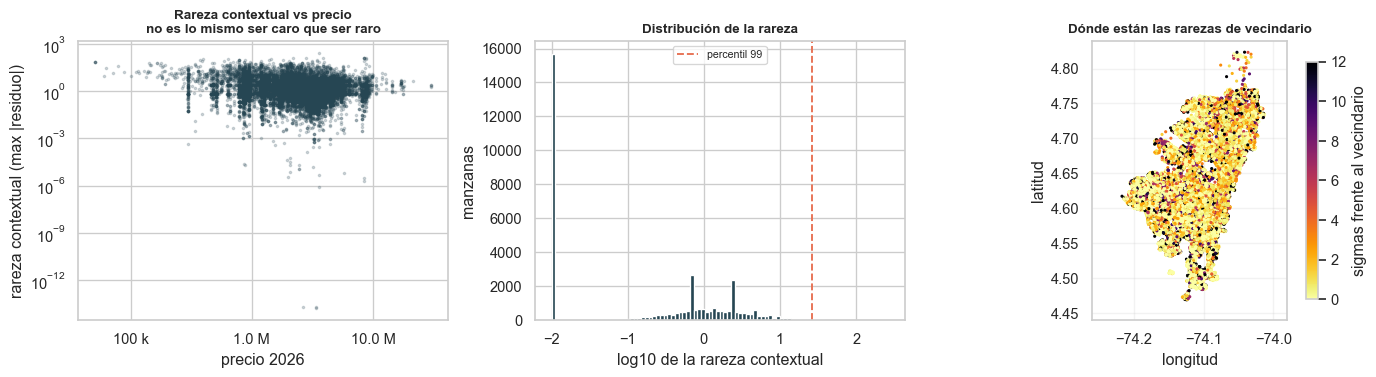

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14.5, 4))

ax[0].scatter(datos["nivel"].map(lambda v: 10 ** v), np.abs(R).max(axis=1),
              s=3, alpha=.2, color=AZUL)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[0].set_xlabel("precio 2026"); ax[0].set_ylabel("rareza contextual (max |residuo|)")
ax[0].set_title("Rareza contextual vs precio\nno es lo mismo ser caro que ser raro")

u = np.abs(R).max(axis=1)
ax[1].hist(np.log10(u + .01), bins=90, color=AZUL)
ax[1].axvline(np.log10(np.percentile(u, 99) + .01), color=ROJO, ls="--", lw=1.4,
              label="percentil 99")
ax[1].set_xlabel("log10 de la rareza contextual"); ax[1].set_ylabel("manzanas")
ax[1].set_title("Distribución de la rareza"); ax[1].legend(fontsize=8)

d = datos[datos["lon"].between(*C.URB_LON) & datos["lat"].between(*C.URB_LAT)].index
s = ax[2].scatter(datos.loc[d, "lon"], datos.loc[d, "lat"], c=np.clip(u[d], 0, 12),
                  s=1.8, cmap="inferno_r")
formato_mapa(ax[2], "Dónde están las rarezas de vecindario")
ax[2].set_ylabel("latitud")
plt.colorbar(s, ax=ax[2], label="sigmas frente al vecindario", shrink=.85)

fig.tight_layout(); guardar_fig(fig, "ano_fig01_residuo_contextual.png"); plt.show()

### 2.2 Siete detectores sobre el mismo residuo

Cada uno define "raro" de otra forma. Conviene tenerlos todos porque más
adelante se va a medir cuál encuentra qué.

| Detector | Qué considera anómalo |
|---|---|
| **Isolation Forest** | lo que se aísla con pocos cortes aleatorios |
| **Local Outlier Factor** | lo que está en una zona menos densa que sus vecinos |
| **One-Class SVM (SGD)** | lo que cae fuera de la frontera que encierra la masa |
| **Elliptic Envelope (MCD)** | lo lejano en distancia de Mahalanobis robusta |
| **Reconstrucción por PCA** | lo que no se puede reconstruir con pocos componentes |
| **Mezcla gaussiana** | lo improbable bajo la densidad estimada |
| **Distancia al k-ésimo vecino** | la línea base: lo que está lejos de todo |

Todos devuelven un puntaje continuo. Se normalizan a **rango percentil** para
poder compararlos y combinarlos: 1.0 es la manzana más anómala según ese método.

In [6]:
Zr = StandardScaler().fit_transform(R)

def a_percentil(puntaje):
    "Convierte cualquier puntaje a rango percentil, donde 1 = lo mas anomalo."
    return pd.Series(puntaje).rank(pct=True).values

def detectores(X, contaminacion=CONTAMINACION, semilla=SEMILLA):
    "Devuelve {nombre: puntaje de anomalia en rango percentil}. Mayor = mas anomalo."
    out = {}
    m = IsolationForest(n_estimators=200, max_samples=256, contamination=contaminacion,
                        random_state=semilla, n_jobs=-1).fit(X)
    out["Isolation Forest"] = a_percentil(-m.score_samples(X))

    lof = LocalOutlierFactor(n_neighbors=20, contamination=contaminacion, n_jobs=-1)
    lof.fit_predict(X)
    out["LOF"] = a_percentil(-lof.negative_outlier_factor_)

    sv = SGDOneClassSVM(nu=max(contaminacion, 0.01), random_state=semilla).fit(X)
    out["One-Class SVM"] = a_percentil(-sv.score_samples(X))

    ee = EllipticEnvelope(support_fraction=.9, contamination=contaminacion,
                          random_state=semilla).fit(X)
    out["Elliptic Envelope"] = a_percentil(-ee.score_samples(X))

    p = PCA(n_components=min(3, X.shape[1])).fit(X)
    out["PCA (reconstruccion)"] = a_percentil(
        ((X - p.inverse_transform(p.transform(X))) ** 2).sum(axis=1))

    g = GaussianMixture(4, covariance_type="full", random_state=semilla, n_init=2).fit(X)
    out["Mezcla gaussiana"] = a_percentil(-g.score_samples(X))

    d, _ = NearestNeighbors(n_neighbors=K_VECINOS + 1).fit(X).kneighbors(X)
    out["Distancia k-esimo vecino"] = a_percentil(d[:, -1])
    return out

t0 = time.time()
puntajes_esp = detectores(Zr)
print("siete detectores ajustados en %.0f s" % (time.time() - t0))
PUNT = pd.DataFrame(puntajes_esp)
PUNT.describe().T[["mean", "min", "max"]].round(3)

siete detectores ajustados en 13 s


,mean,min,max
Isolation Forest,0.5,0.211,1.0
LOF,0.5,0.000,1.0
One-Class SVM,0.5,0.000,1.0
Elliptic Envelope,0.5,0.000,1.0
PCA (reconstruccion),0.5,0.000,1.0
Mezcla gaussiana,0.5,0.000,1.0
Distancia k-esimo vecino,0.5,0.213,1.0


### 2.3 Rejilla de hiperparámetros

In [7]:
def marcadas(p, frac=CONTAMINACION):
    "Indices de las manzanas en el frac superior del puntaje."
    return set(np.argsort(-p)[:int(frac * len(p))])

base = marcadas(puntajes_esp["LOF"])
filas = []
for k in GRID_LOF:
    lof = LocalOutlierFactor(n_neighbors=k, contamination=CONTAMINACION, n_jobs=-1)
    lof.fit_predict(Zr)
    p = a_percentil(-lof.negative_outlier_factor_)
    filas.append({"detector": "LOF", "parametro": "n_neighbors=%d" % k,
                  "solape_con_k20": round(len(marcadas(p) & base) / max(len(base), 1), 3)})
for n_est, max_s in GRID_IFOREST:
    m = IsolationForest(n_estimators=n_est, max_samples=max_s, contamination=CONTAMINACION,
                        random_state=SEMILLA, n_jobs=-1).fit(Zr)
    p = a_percentil(-m.score_samples(Zr))
    filas.append({"detector": "Isolation Forest",
                  "parametro": "n=%d, max_samples=%s" % (n_est, max_s),
                  "solape_con_k20": round(
                      len(marcadas(p) & marcadas(puntajes_esp["Isolation Forest"]))
                      / max(len(base), 1), 3)})
for sf in GRID_MCD:
    ee = EllipticEnvelope(support_fraction=sf, contamination=CONTAMINACION,
                          random_state=SEMILLA).fit(Zr)
    p = a_percentil(-ee.score_samples(Zr))
    filas.append({"detector": "Elliptic Envelope", "parametro": "support_fraction=%.2f" % sf,
                  "solape_con_k20": round(
                      len(marcadas(p) & marcadas(puntajes_esp["Elliptic Envelope"]))
                      / max(len(base), 1), 3)})
for nc in GRID_PCA:
    p_ = PCA(n_components=min(nc, Zr.shape[1])).fit(Zr)
    p = a_percentil(((Zr - p_.inverse_transform(p_.transform(Zr))) ** 2).sum(axis=1))
    filas.append({"detector": "PCA (reconstruccion)", "parametro": "componentes=%d" % nc,
                  "solape_con_k20": round(
                      len(marcadas(p) & marcadas(puntajes_esp["PCA (reconstruccion)"]))
                      / max(len(base), 1), 3)})

rejilla = pd.DataFrame(filas)
guardar_tabla(rejilla, "t56_rejilla_detectores.csv", index=False)
print("Cada fila: cuanto coincide la lista de marcadas con la configuracion por defecto.")
print("Un solape bajo significa que el hiperparametro cambia POR COMPLETO la respuesta,")
print("y que el numero que se reporte dependera mas de el que del fenomeno.\n")
rejilla

Cada fila: cuanto coincide la lista de marcadas con la configuracion por defecto.
Un solape bajo significa que el hiperparametro cambia POR COMPLETO la respuesta,
y que el numero que se reporte dependera mas de el que del fenomeno.



,detector,parametro,solape_con_k20
0,LOF,n_neighbors=5,0.107
1,LOF,n_neighbors=10,0.575
2,LOF,n_neighbors=20,1.000
3,LOF,n_neighbors=35,0.634
4,LOF,n_neighbors=50,0.484
5,Isolation Forest,"n=100, max_samples=256",0.939
6,Isolation Forest,"n=200, max_samples=256",1.000
7,Isolation Forest,"n=200, max_samples=1024",0.872
8,Isolation Forest,"n=400, max_samples=auto",0.957
9,Elliptic Envelope,support_fraction=0.75,0.984


### 2.4 ¿Están mirando lo mismo?

Correlación de rangos entre los siete puntajes y solapamiento de sus listas de
marcadas. Si dos detectores correlacionan 0.95 no hace falta tener los dos; si
correlacionan 0.2, alguno está equivocado —o están viendo cosas distintas y eso
es información.

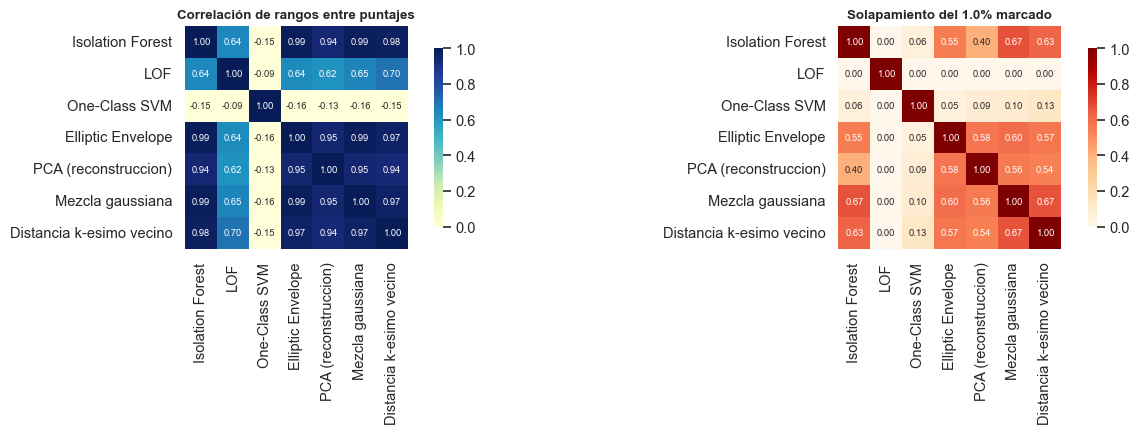

manzanas marcadas por al menos un detector : 1438
marcadas por la mayoria (>= 4 de 7)       : 235
marcadas por los siete                      : 0


In [8]:
corr = PUNT.corr(method="spearman")
guardar_tabla(corr.round(3), "t57_acuerdo_detectores_espaciales.csv")

sets = {n: marcadas(p) for n, p in puntajes_esp.items()}
n_det = len(sets)
solape = pd.DataFrame(index=list(sets), columns=list(sets), dtype=float)
for a in sets:
    for b in sets:
        solape.loc[a, b] = len(sets[a] & sets[b]) / max(len(sets[a]), 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, square=True,
            annot_kws={"size": 7}, cbar_kws={"shrink": .8}, ax=ax[0])
ax[0].set_title("Correlación de rangos entre puntajes")
sns.heatmap(solape.astype(float), annot=True, fmt=".2f", cmap="OrRd", vmin=0, vmax=1,
            square=True, annot_kws={"size": 7}, cbar_kws={"shrink": .8}, ax=ax[1])
ax[1].set_title("Solapamiento del %.1f%% marcado" % (100 * CONTAMINACION))
fig.tight_layout(); guardar_fig(fig, "ano_fig02_acuerdo.png"); plt.show()

votos = np.zeros(len(datos), dtype=int)
for s in sets.values():
    votos[list(s)] += 1
print("manzanas marcadas por al menos un detector : %d" % (votos >= 1).sum())
print("marcadas por la mayoria (>= %d de %d)       : %d" % (n_det // 2 + 1, n_det,
                                                            (votos >= n_det // 2 + 1).sum()))
print("marcadas por los siete                      : %d" % (votos == n_det).sum())

## 3. Parte B — anomalías temporales: ¿en qué año se rompió?

Cambia la unidad de análisis. Ya no es la manzana sino la **transición**: el par
(manzana, año), con una fila por cada salto anual de la serie. Son nueve por
manzana y unas 337 mil en total.

Cada transición se describe por cinco cosas, y la gracia está en que tres de
ellas son **de contexto**: lo que hizo la ciudad ese año, lo que hicieron los
vecinos ese año y lo que venía haciendo la propia manzana. Un crecimiento del
40 % no es anómalo si toda la ciudad creció 40 %; lo es si nadie más se movió.

In [9]:
anios_t = [a for a in G.columns]
pos = {m: i for i, m in enumerate(datos["manzana"])}
Gm = G.loc[datos["manzana"]].values                     # (n_manzanas, n_anios)

g_ciudad = np.median(Gm, axis=0)                        # deriva de la ciudad cada año
g_vecinos = Gm[IDX].mean(axis=1)                        # (n, n_anios)
g_previo = np.c_[np.full(len(Gm), np.nan), Gm[:, :-1]]

sector_cod = datos["sector"].values
g_sector = pd.DataFrame(Gm, index=sector_cod).groupby(level=0).transform("median").values

n, T = Gm.shape
trans = pd.DataFrame({
    "manzana": np.repeat(datos["manzana"].values, T),
    "sector": np.repeat(sector_cod, T),
    "anio": np.tile(anios_t, n),
    "g": Gm.ravel(),
    "g_ciudad": np.tile(g_ciudad, n),
    "g_vecinos": g_vecinos.ravel(),
    "g_sector": g_sector.ravel(),
    "g_previo": g_previo.ravel(),
})
trans["r_ciudad"] = trans["g"] - trans["g_ciudad"]
trans["r_vecinos"] = trans["g"] - trans["g_vecinos"]
trans["r_sector"] = trans["g"] - trans["g_sector"]
trans = trans.dropna().reset_index(drop=True)

RASGOS_T = ["g", "r_ciudad", "r_vecinos", "r_sector", "g_previo"]
print("transiciones utiles: %d  (%d manzanas x %d años)" % (len(trans), n, T - 1))
print()
print("desviacion tipica del crecimiento, segun contra que se mida:")
print("  crudo (g)                : %.4f" % trans["g"].std())
print("  menos la ciudad          : %.4f" % trans["r_ciudad"].std())
print("  menos los vecinos        : %.4f  <- el contexto local explica mas" % trans["r_vecinos"].std())
trans.head(3)

transiciones utiles: 299536  (37442 manzanas x 8 años)

desviacion tipica del crecimiento, segun contra que se mida:
  crudo (g)                : 0.0713
  menos la ciudad          : 0.0698
  menos los vecinos        : 0.0540  <- el contexto local explica mas


,manzana,sector,anio,g,g_ciudad,g_vecinos,g_sector,g_previo,r_ciudad,r_vecinos,r_sector
0,005635004,005635,2019,0.037789,0.041393,0.038690,0.037789,0.041393,-0.003604,-0.000901,0.0
1,005635004,005635,2020,0.026329,0.041393,0.035776,0.026329,0.037789,-0.015064,-0.009447,0.0
2,005635004,005635,2021,0.019971,0.032185,0.019971,0.019971,0.026329,-0.012214,0.000000,0.0


### 3.1 Tres detectores sobre las transiciones

Para esta parte bastan tres: dos de los anteriores, que ya mostraron su
comportamiento, y uno específico —el **z robusto contra la propia historia de la
manzana**, que pregunta si ese año fue raro *para ella*, no para el conjunto.

In [10]:
Zt = StandardScaler().fit_transform(trans[RASGOS_T].values)

t0 = time.time()
ift = IsolationForest(n_estimators=150, max_samples=256, contamination=CONTAMINACION,
                      random_state=SEMILLA, n_jobs=-1).fit(Zt)
trans["p_iforest"] = a_percentil(-ift.score_samples(Zt))

lof_t = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINACION, n_jobs=-1)
lof_t.fit_predict(Zt)
trans["p_lof"] = a_percentil(-lof_t.negative_outlier_factor_)

# z robusto de cada transicion contra las otras transiciones de la MISMA manzana
med_i = trans.groupby("manzana")["r_ciudad"].transform("median")
mad_i = trans.groupby("manzana")["r_ciudad"].transform(
    lambda s: np.median(np.abs(s - np.median(s))))
piso = np.median(mad_i[mad_i > 0])
trans["z_propio"] = (trans["r_ciudad"] - med_i) / (1.4826 * mad_i.clip(lower=piso))
trans["p_zpropio"] = a_percentil(np.abs(trans["z_propio"]))

trans["consenso_t"] = trans[["p_iforest", "p_lof", "p_zpropio"]].mean(axis=1)
print("tres detectores sobre %d transiciones en %.0f s" % (len(trans), time.time() - t0))
print()
print("correlacion de rangos entre ellos:")
print(trans[["p_iforest", "p_lof", "p_zpropio"]].corr(method="spearman").round(3).to_string())

tres detectores sobre 299536 transiciones en 26 s

correlacion de rangos entre ellos:
           p_iforest  p_lof  p_zpropio
p_iforest      1.000  0.116      0.524
p_lof          0.116  1.000      0.059
p_zpropio      0.524  0.059      1.000


### 3.2 El año del quiebre y de qué tipo fue

Además del puntaje, interesa **dónde** se parte la serie. Se busca, para cada
manzana, el corte que más separa el crecimiento medio de antes y el de después
—una búsqueda exhaustiva sobre los ocho cortes posibles, que con series de diez
puntos es barata y exacta—. Después cada manzana se etiqueta según qué le pasó.

In [11]:
def quiebre_de_tendencia(M):
    "Para cada fila, el corte que maximiza |media_antes - media_despues| y su tamaño."
    n_, T_ = M.shape
    acum = np.cumsum(M, axis=1)
    mejor_val = np.zeros(n_); mejor_pos = np.zeros(n_, dtype=int)
    for s in range(2, T_ - 1):                      # al menos 2 puntos a cada lado
        antes = acum[:, s - 1] / s
        despues = (acum[:, -1] - acum[:, s - 1]) / (T_ - s)
        d = np.abs(despues - antes)
        mejora = d > mejor_val
        mejor_val[mejora] = d[mejora]; mejor_pos[mejora] = s
    return mejor_val, mejor_pos

salto_val, salto_pos = quiebre_de_tendencia(Gm)
datos["quiebre_magnitud"] = salto_val
datos["quiebre_anio"] = [anios_t[p] for p in salto_pos]

# el año mas anomalo de cada manzana segun el consenso de los tres detectores
peor = trans.loc[trans.groupby("manzana")["consenso_t"].idxmax(),
                 ["manzana", "anio", "g", "r_ciudad", "r_sector", "consenso_t", "z_propio"]]
peor = peor.rename(columns={"anio": "anio_peor", "g": "g_peor"})
datos = datos.merge(peor, on="manzana", how="left")

def tipo_de_ruptura(f):
    if f["g_peor"] == 0:
        return "congelamiento"
    if f["r_ciudad"] > 0.08:
        return "salto"
    if f["r_ciudad"] < -0.08:
        return "caida"
    if f["quiebre_magnitud"] > 0.04:
        return "quiebre de tendencia"
    return "sin ruptura clara"

datos["tipo_ruptura"] = datos.apply(tipo_de_ruptura, axis=1)
resumen_tipo = (datos["tipo_ruptura"].value_counts().to_frame("manzanas")
                .assign(pct=lambda d: (100 * d["manzanas"] / len(datos)).round(1)))
guardar_tabla(resumen_tipo, "t58_tipos_de_ruptura.csv")
print("año en que se concentra el peor quiebre:")
print(datos["anio_peor"].value_counts().sort_index().to_string())
print()
resumen_tipo

año en que se concentra el peor quiebre:
anio_peor
2019    9073
2020    7121
2021    5578
2022      37
2023    2706
2024    2076
2025    1473
2026    9378



,manzanas,pct
tipo_ruptura,,
sin ruptura clara,16541,44.2
quiebre de tendencia,9638,25.7
salto,6420,17.1
congelamiento,2926,7.8
caida,1917,5.1


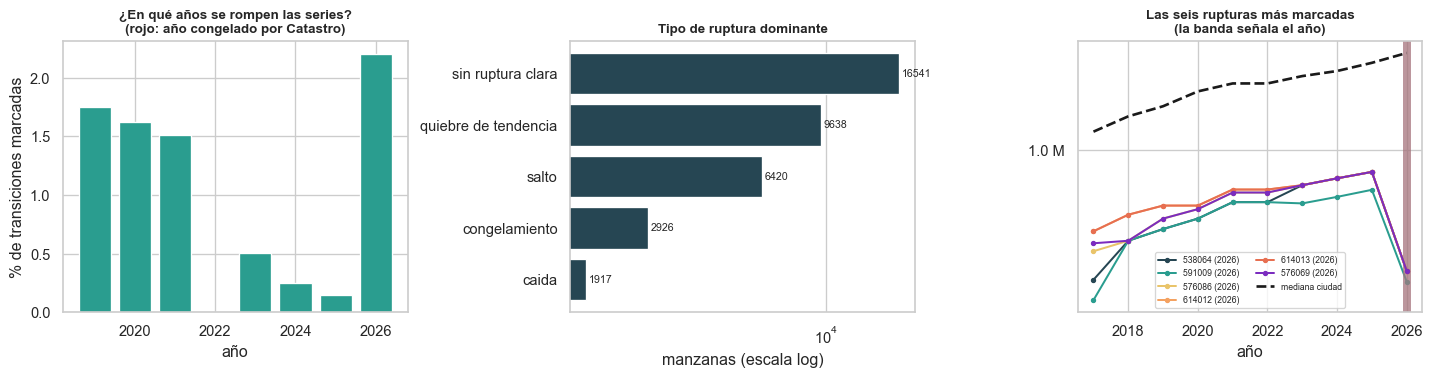

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

umbral = np.percentile(trans["consenso_t"], 100 * (1 - CONTAMINACION))
por_anio = trans.assign(marcada=trans["consenso_t"] > umbral).groupby("anio")["marcada"].mean() * 100
ax[0].bar(por_anio.index, por_anio.values,
          color=[ROJO if a in CONGELADOS else VERDE for a in por_anio.index])
ax[0].set_xlabel("año"); ax[0].set_ylabel("% de transiciones marcadas")
ax[0].set_title("¿En qué años se rompen las series?\n(rojo: año congelado por Catastro)")

orden = resumen_tipo.index.tolist()
ax[1].barh(orden[::-1], resumen_tipo.loc[orden[::-1], "manzanas"], color=AZUL)
for i, v in enumerate(resumen_tipo.loc[orden[::-1], "manzanas"]):
    ax[1].text(v * 1.02, i, "%d" % v, va="center", fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("manzanas (escala log)")
ax[1].set_title("Tipo de ruptura dominante"); ax[1].grid(axis="y", alpha=0)

top6 = datos.nlargest(6, "consenso_t")
for i, (_, f) in enumerate(top6.iterrows()):
    serie = 10 ** LOG.loc[f["manzana"]]
    ax[2].plot(serie.index, serie.values, "o-", lw=1.5, ms=3, color=PALETA[i % len(PALETA)],
               label="%s (%d)" % (f["manzana"][-6:], f["anio_peor"]))
    ax[2].axvline(f["anio_peor"], color=PALETA[i % len(PALETA)], alpha=.2, lw=6)
ax[2].plot(ancha.columns, ancha.median(), "k--", lw=2, label="mediana ciudad")
ax[2].set_yscale("log"); ax[2].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[2].set_xlabel("año"); ax[2].set_title("Las seis rupturas más marcadas\n(la banda señala el año)")
ax[2].legend(fontsize=6.5, ncol=2)

fig.tight_layout(); guardar_fig(fig, "ano_fig03_temporales.png"); plt.show()

## 4. Parte C — ¿sirven estos detectores? Anomalías sintéticas

Hasta aquí hay siete puntajes espaciales y tres temporales, y ninguna razón para
creerle a uno más que a otro. Sin etiquetas no hay manera de medir acierto… a
menos que se fabriquen.

El procedimiento: se toma una copia de los datos, se **inyectan anomalías
construidas a propósito** en manzanas elegidas al azar, se vuelve a correr todo
el pipeline y se mide qué fracción recupera cada detector. Como se sabe
exactamente cuáles son, se pueden calcular precisión y recall de verdad.

### 4.1 Cómo se construye una anomalía *contextual*

El detalle que hace válida la prueba: la anomalía inyectada tiene que ser rara
**para su vecindario** y a la vez **normal para la ciudad**. Si se inyectara un
precio de 80 millones, cualquier detector la encontraría y la prueba no diría
nada. Por eso el precio alterado se **recorta al rango central de la ciudad**:
la manzana sigue siendo un precio perfectamente corriente en Bogotá, solo que
imposible en esa cuadra.

Se inyectan tres magnitudes —0.5, 1 y 2 desviaciones del vecindario— para poder
separar lo fácil de lo sutil, que es donde los detectores se diferencian.

In [13]:
rng_iny = np.random.default_rng(SEMILLA + 7)
M_sucio = M.copy()
etiqueta = np.zeros(len(M), dtype=int)       # 0 = limpia
magnitud = np.zeros(len(M))

# se inyecta en la MISMA escala con piso que usa el detector; con el MAD crudo
# del vecindario la perturbacion seria de cero en el 70% de los casos
_, ESC, _ = escala_local(M)
lim_bajo, lim_alto = np.percentile(M, 2, axis=0), np.percentile(M, 98, axis=0)

candidatas = rng_iny.permutation(len(M))[:N_INYECTADAS * len(MAGNITUDES)]
bloques = np.array_split(candidatas, len(MAGNITUDES))
for mag, bloque in zip(MAGNITUDES, bloques):
    # una sola variable por manzana, elegida al azar: una anomalia en dos variables
    # a la vez seria demasiado facil de encontrar
    cual = rng_iny.choice([RASGOS.index("nivel"), RASGOS.index("cagr_reciente")], len(bloque))
    signo = rng_iny.choice([-1, 1], len(bloque))
    M_sucio[bloque, cual] = np.clip(
        M[bloque, cual] + signo * mag * ESC[bloque, cual],
        lim_bajo[cual], lim_alto[cual])
    etiqueta[bloque] = 1
    magnitud[bloque] = mag

movidas = (np.abs(M_sucio - M).max(axis=1) > 1e-9)
print("manzanas inyectadas: %d de %d (%.1f%%)" % (movidas.sum(), len(M), 100 * movidas.mean()))
print()
print("comprobacion de que son anomalias CONTEXTUALES y no globales:")
glob = np.abs((M_sucio - M_sucio.mean(0)) / M_sucio.std(0)).max(axis=1)
print("  |z| global mediano de las inyectadas : %.2f" % np.median(glob[movidas]))
print("  |z| global mediano del resto         : %.2f" % np.median(glob[~movidas]))
print("  -> a escala de ciudad son indistinguibles, como debe ser")

manzanas inyectadas: 1199 de 37442 (3.2%)

comprobacion de que son anomalias CONTEXTUALES y no globales:
  |z| global mediano de las inyectadas : 0.96
  |z| global mediano del resto         : 0.86
  -> a escala de ciudad son indistinguibles, como debe ser


In [14]:
R_sucio = residuo_contextual(M_sucio)
Zr_sucio = StandardScaler().fit_transform(R_sucio)
t0 = time.time()
puntajes_sucio = detectores(Zr_sucio, semilla=SEMILLA + 1)
print("detectores reajustados sobre los datos contaminados en %.0f s\n" % (time.time() - t0))

def recall_en_k(p, y, k):
    top = np.argsort(-p)[:k]
    return y[top].sum() / max(y.sum(), 1)

k_rev = int(CONTAMINACION * len(M))
filas = []
for nombre, p in puntajes_sucio.items():
    f = {"detector": nombre,
         "average_precision": round(average_precision_score(etiqueta, p), 3),
         "roc_auc": round(roc_auc_score(etiqueta, p), 3),
         "recall_en_%d" % k_rev: round(recall_en_k(p, etiqueta, k_rev), 3)}
    for mag in MAGNITUDES:
        y_mag = ((etiqueta == 1) & (magnitud == mag)).astype(int)
        solo = (etiqueta == 0) | (magnitud == mag)
        f["recall_%.1f_sigma" % mag] = round(
            average_precision_score(y_mag[solo], p[solo]), 3)
    filas.append(f)
desempeno = pd.DataFrame(filas).sort_values("average_precision", ascending=False)
guardar_tabla(desempeno, "t59_desempeno_sinteticas.csv", index=False)
print("Una anomalia al azar tendria average_precision = %.3f (la tasa base)."
      % etiqueta.mean())
desempeno

detectores reajustados sobre los datos contaminados en 13 s



Una anomalia al azar tendria average_precision = 0.032 (la tasa base).


,detector,average_precision,roc_auc,recall_en_374,recall_0.5_sigma,recall_1.0_sigma,recall_2.0_sigma
1,LOF,0.115,0.608,0.118,0.019,0.044,0.123
4,PCA (reconstruccion),0.083,0.817,0.012,0.020,0.028,0.050
3,Elliptic Envelope,0.062,0.761,0.012,0.017,0.021,0.033
5,Mezcla gaussiana,0.058,0.740,0.015,0.016,0.019,0.029
0,Isolation Forest,0.055,0.732,0.016,0.015,0.019,0.026
2,One-Class SVM,0.054,0.525,0.018,0.014,0.019,0.032
6,Distancia k-esimo vecino,0.041,0.580,0.015,0.013,0.015,0.015


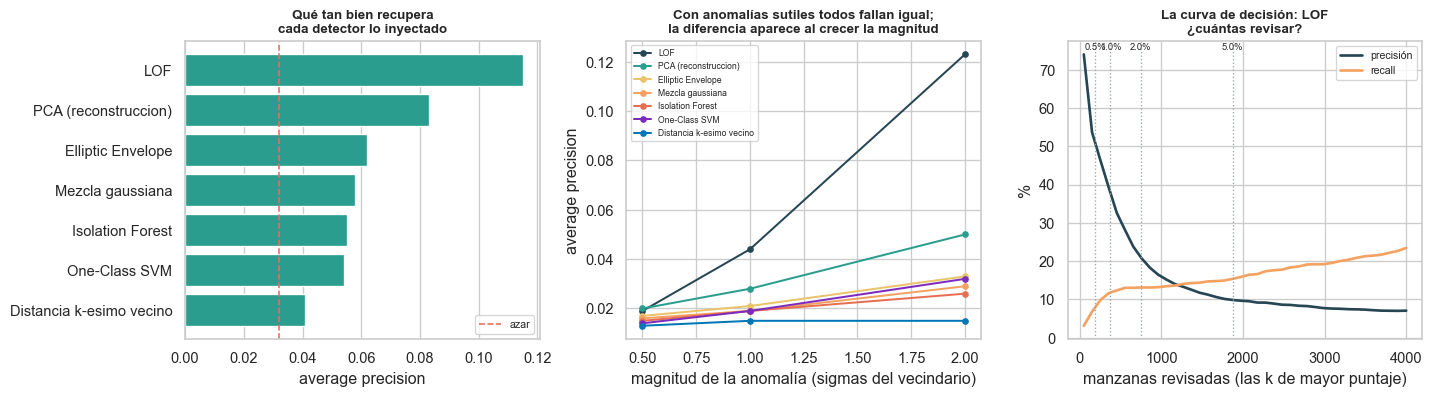

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

o = desempeno.sort_values("average_precision")
ax[0].barh(o["detector"], o["average_precision"], color=VERDE)
ax[0].axvline(etiqueta.mean(), color=ROJO, ls="--", lw=1.2, label="azar")
ax[0].set_xlabel("average precision"); ax[0].set_title("Qué tan bien recupera\ncada detector lo inyectado")
ax[0].legend(fontsize=8); ax[0].grid(axis="y", alpha=0)

cols = ["recall_%.1f_sigma" % m for m in MAGNITUDES]
for i, (_, f) in enumerate(desempeno.iterrows()):
    ax[1].plot(MAGNITUDES, [f[c] for c in cols], "o-", lw=1.5, ms=4,
               color=PALETA[i % len(PALETA)], label=f["detector"])
ax[1].set_xlabel("magnitud de la anomalía (sigmas del vecindario)")
ax[1].set_ylabel("average precision")
ax[1].set_title("Con anomalías sutiles todos fallan igual;\nla diferencia aparece al crecer la magnitud")
ax[1].legend(fontsize=6.5)

mejor = desempeno.iloc[0]["detector"]
p = puntajes_sucio[mejor]
ks = np.unique(np.linspace(50, 4000, 40).astype(int))
ax[2].plot(ks, [100 * etiqueta[np.argsort(-p)[:k]].mean() for k in ks], lw=2, color=AZUL,
           label="precisión")
ax[2].plot(ks, [100 * recall_en_k(p, etiqueta, k) for k in ks], lw=2, color=NARANJA,
           label="recall")
for frac in CURVA_CONTAMINACION:
    ax[2].axvline(frac * len(M), color=GRIS, ls=":", lw=1)
    ax[2].text(frac * len(M), .97, "%.1f%%" % (100 * frac), fontsize=7, ha="center",
               transform=ax[2].get_xaxis_transform())
ax[2].set_xlabel("manzanas revisadas (las k de mayor puntaje)")
ax[2].set_ylabel("%"); ax[2].set_title("La curva de decisión: %s\n¿cuántas revisar?" % mejor)
ax[2].legend(fontsize=8)

fig.tight_layout(); guardar_fig(fig, "ano_fig04_sinteticas.png"); plt.show()

### 4.2 Dos métricas que cuentan historias opuestas

La tabla trae `average_precision` y `roc_auc`, y **no coinciden**: hay
detectores con ROC muy alto y precisión media baja. No es contradicción, es la
asimetría de clases. Con un 3 % de anomalías, el ROC se calcula sobre un
universo dominado por los negativos y premia a quien ordena bien *el montón*;
la precisión media solo mira la **cabeza de la lista**, que es lo único que
alguien va a revisar. Para detección de anomalías manda la segunda.

El `recall` tiene además un techo que conviene tener presente: si se revisan
*k* manzanas y hay *p* anómalas, el recall no puede pasar de *k/p* por mucho
que el detector sea perfecto. Por eso la curva de abajo reporta también
precisión, que no tiene ese techo.

### 4.3 La curva de contaminación: cuántas revisar

Esta tabla es la decisión operativa. No hay un umbral correcto: hay un
intercambio entre cuántas manzanas se está dispuesto a mirar a mano y qué
fracción de lo anómalo se deja escapar.

In [16]:
filas = []
for frac in CURVA_CONTAMINACION:
    k = int(frac * len(M))
    top = np.argsort(-p)[:k]
    filas.append({"contaminacion": "%.1f%%" % (100 * frac), "manzanas_a_revisar": k,
                  "precision_pct": round(100 * etiqueta[top].mean(), 1),
                  "recall_pct": round(100 * recall_en_k(p, etiqueta, k), 1)})
curva = pd.DataFrame(filas)
guardar_tabla(curva, "t60_curva_contaminacion.csv", index=False)
print("Medido con el mejor detector (%s) sobre las anomalias inyectadas.\n" % mejor)
curva

Medido con el mejor detector (LOF) sobre las anomalias inyectadas.



,contaminacion,manzanas_a_revisar,precision_pct,recall_pct
0,0.5%,187,51.9,8.1
1,1.0%,374,37.7,11.8
2,2.0%,748,21.0,13.1
3,5.0%,1872,9.8,15.3


## 5. Parte D — la lista priorizada

Se vuelve a los datos reales. Cada manzana recibe:

- un **puntaje de consenso**, el promedio de los siete rangos percentiles;
- el **número de detectores** que la marcan;
- el **motivo**: qué rasgo se aleja más de su vecindario, y en qué dirección;
- el **año y el tipo** de su ruptura temporal;
- y una **clasificación** en dos cubetas.

### La distinción que importa

El notebook de clusters ya avisó que la mayoría de las rarezas de esta base son
**administrativas**. Aquí se separan con una regla que usa el dato disponible:

> Si una manzana saltó el mismo año y en la misma magnitud que **todo su
> sector**, fue Catastro revaluando la zona. Si saltó mientras su sector se
> quedaba quieto, es una rareza **aislada** —y esa es la que vale la pena
> mirar, sea señal de mercado o error de dato.

Una advertencia sobre dónde aplicar esa regla. Sobre la **lista espacial** está
casi viciada: un detector espacial marca precisamente a las manzanas que se
apartan de su entorno, así que casi todas van a salir "aisladas" por
construcción. Donde la regla sí discrimina es sobre las **transiciones** —ahí
la pregunta "¿saltó el sector entero ese año?" es genuina— y por eso se reporta
en los dos niveles, con el segundo como el informativo.

In [17]:
datos["consenso_esp"] = PUNT.mean(axis=1).values
datos["n_detectores"] = votos
nombres_rasgo = {"nivel": "precio", "cagr_total": "valorizacion total",
                 "cagr_reciente": "valorizacion reciente", "volatilidad": "volatilidad",
                 "inercia": "inercia"}
j = np.abs(R).argmax(axis=1)
datos["motivo"] = [("%s %s que su vecindario"
                    % (nombres_rasgo[RASGOS[c]], "mas alto" if R[i, c] > 0 else "mas bajo"))
                   for i, c in enumerate(j)]
datos["motivo_sigmas"] = np.round(R[np.arange(len(R)), j], 1)

# artefacto vs aislada: ¿se movio el sector entero ese año?
# r_ciudad = g - g_ciudad   y   r_sector = g - g_sector,  asi que su diferencia
# es g_sector - g_ciudad: cuanto se aparto el SECTOR ENTERO de la ciudad ese año
desvio_del_sector = (datos["r_ciudad"] - datos["r_sector"]).abs()
hizo_lo_mismo_que_su_sector = datos["r_sector"].abs() < 0.02
sector_se_movio = desvio_del_sector > 0.03
datos["clasificacion"] = np.where(
    datos["tipo_ruptura"] == "sin ruptura clara", "sin ruptura temporal",
    np.where(hizo_lo_mismo_que_su_sector & sector_se_movio, "artefacto administrativo (revaluo de zona)",
             "aislada: posible señal de mercado"))

marcadas_esp = datos["n_detectores"] >= (n_det // 2 + 1)
datos["marcada"] = marcadas_esp
reparto = (datos[marcadas_esp]["clasificacion"].value_counts().to_frame("manzanas")
           .assign(pct=lambda d: (100 * d["manzanas"] / marcadas_esp.sum()).round(1)))
guardar_tabla(reparto, "t61_artefacto_vs_senal.csv")
print("de las %d manzanas marcadas por la mayoria de los detectores:" % marcadas_esp.sum())
print("(sesgado hacia 'aislada' por construccion, ver la nota de arriba)")
print(reparto.to_string())

# la misma regla donde si discrimina: sobre las transiciones mas anomalas
umbral_t = np.percentile(trans["consenso_t"], 99)
top_t = trans[trans["consenso_t"] > umbral_t].copy()
top_t["clasificacion"] = np.where(
    (top_t["r_sector"].abs() < 0.02) & ((top_t["r_ciudad"] - top_t["r_sector"]).abs() > 0.03),
    "artefacto administrativo (revaluo de zona)", "aislada: posible señal de mercado")
reparto_t = (top_t["clasificacion"].value_counts().to_frame("transiciones")
             .assign(pct=lambda d: (100 * d["transiciones"] / len(top_t)).round(1)))
guardar_tabla(reparto_t, "t61b_artefacto_vs_senal_transiciones.csv")
por_anio_clase = pd.crosstab(top_t["anio"], top_t["clasificacion"])
guardar_tabla(por_anio_clase, "t61c_clasificacion_por_anio.csv")

print()
print("y sobre el 1%% de transiciones mas anomalas (%d), donde la regla si separa:" % len(top_t))
print(reparto_t.to_string())
print()
print("reparto por año:")
print(por_anio_clase.to_string())

de las 235 manzanas marcadas por la mayoria de los detectores:
(sesgado hacia 'aislada' por construccion, ver la nota de arriba)
                                            manzanas   pct
clasificacion                                             
aislada: posible señal de mercado                194  82.6
artefacto administrativo (revaluo de zona)        35  14.9
sin ruptura temporal                               6   2.6

y sobre el 1% de transiciones mas anomalas (2996), donde la regla si separa:
                                            transiciones   pct
clasificacion                                                 
aislada: posible señal de mercado                   1610  53.7
artefacto administrativo (revaluo de zona)          1386  46.3

reparto por año:
clasificacion  aislada: posible señal de mercado  artefacto administrativo (revaluo de zona)
anio                                                                                        
2019                                      

In [18]:
lista = (datos[marcadas_esp]
         .sort_values("consenso_esp", ascending=False)
         [["manzana", "sector", "cagr_reciente", "nivel", "n_detectores", "consenso_esp",
           "motivo", "motivo_sigmas", "anio_peor", "tipo_ruptura", "clasificacion"]]
         .reset_index(drop=True))
lista["precio_2026"] = (10 ** lista["nivel"]).round(0)
lista = lista.drop(columns=["nivel", "cagr_reciente"])
guardar_tabla(lista.head(200), "t62_lista_priorizada.csv", index=False)

aisladas = lista[lista["clasificacion"].str.startswith("aislada")]
print("TOP 12 de rarezas AISLADAS (las que no se explican por un revaluo de zona)\n")
vista = aisladas.head(12).copy()
vista["precio_2026"] = vista["precio_2026"].map(pesos)
print(vista[["manzana", "sector", "precio_2026", "n_detectores", "motivo",
             "motivo_sigmas", "anio_peor", "tipo_ruptura"]].to_string(index=False))

TOP 12 de rarezas AISLADAS (las que no se explican por un revaluo de zona)

  manzana sector precio_2026  n_detectores                                           motivo  motivo_sigmas  anio_peor         tipo_ruptura
001325032 001325       873 k             6           volatilidad mas alto que su vecindario           56.9       2019                salto
008540013 008540       2.2 M             5           volatilidad mas bajo que su vecindario          -17.7       2023 quiebre de tendencia
002552066 002552       940 k             6           volatilidad mas alto que su vecindario           43.9       2019                salto
002548001 002548       2.2 M             5           volatilidad mas bajo que su vecindario          -27.4       2022        congelamiento
002410001 002410       1.2 M             6           volatilidad mas alto que su vecindario           39.3       2021                salto
002302020 002302       2.8 M             4 valorizacion reciente mas alto que su vecindari

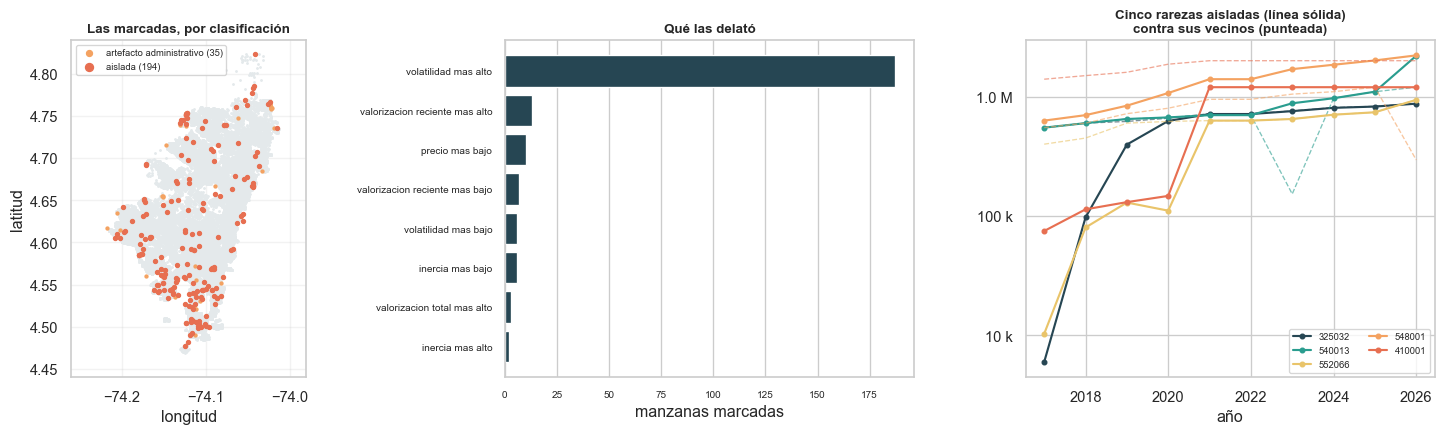

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.6))

d = datos[datos["lon"].between(*C.URB_LON) & datos["lat"].between(*C.URB_LAT)]
ax[0].scatter(d["lon"], d["lat"], s=1.2, color="#e4e9eb")
for etq, col, tam in [("artefacto administrativo (revaluo de zona)", NARANJA, 5),
                      ("aislada: posible señal de mercado", ROJO, 9)]:
    m = d["marcada"] & (d["clasificacion"] == etq)
    ax[0].scatter(d.loc[m, "lon"], d.loc[m, "lat"], s=tam, color=col,
                  label="%s (%d)" % (etq.split(":")[0].split("(")[0].strip(), m.sum()))
formato_mapa(ax[0], "Las marcadas, por clasificación")
ax[0].set_ylabel("latitud"); ax[0].legend(fontsize=7, markerscale=2, loc="upper left")

conteo = (datos[marcadas_esp]["motivo"].str.replace(" que su vecindario", "", regex=False)
          .value_counts().head(8).iloc[::-1])
ax[1].barh(conteo.index, conteo.values, color=AZUL)
ax[1].set_xlabel("manzanas marcadas"); ax[1].set_title("Qué las delató")
ax[1].grid(axis="y", alpha=0); ax[1].tick_params(labelsize=7.5)

for i, (_, f) in enumerate(aisladas.head(5).iterrows()):
    serie = 10 ** LOG.loc[f["manzana"]]
    ax[2].plot(serie.index, serie.values, "o-", lw=1.6, ms=3.5,
               color=PALETA[i % len(PALETA)], label=f["manzana"][-6:])
    vecinas = datos.loc[IDX[pos[f["manzana"]]], "manzana"]
    ax[2].plot(ancha.columns, (10 ** LOG.loc[vecinas]).median(),
               "--", lw=1, alpha=.6, color=PALETA[i % len(PALETA)])
ax[2].set_yscale("log"); ax[2].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[2].set_xlabel("año")
ax[2].set_title("Cinco rarezas aisladas (línea sólida)\ncontra sus vecinos (punteada)")
ax[2].legend(fontsize=7, ncol=2)

fig.tight_layout(); guardar_fig(fig, "ano_fig05_lista.png"); plt.show()

### El archivo de salida

In [20]:
salida = datos[["manzana", "sector", "lon", "lat", "nivel", "cagr_total", "cagr_reciente",
                "volatilidad", "inercia", "consenso_esp", "n_detectores", "marcada",
                "motivo", "motivo_sigmas", "anio_peor", "quiebre_anio", "quiebre_magnitud",
                "tipo_ruptura", "clasificacion"]].copy()
salida["precio_2026"] = (10 ** salida["nivel"]).round(0)
for nombre, p_ in puntajes_esp.items():
    salida["p_" + nombre.split()[0].lower().replace("(", "")] = np.round(p_, 4)
salida.to_csv(F_SALIDA, index=False)

trans_top = trans[trans["consenso_t"] > np.percentile(trans["consenso_t"], 99)]
trans_top.to_csv(F_SALIDA_T, index=False)

print("guardado: %s | %d manzanas x %d columnas" % (F_SALIDA.name, *salida.shape))
print("guardado: %s | %d transiciones (el 1%% mas anomalo)"
      % (F_SALIDA_T.name, len(trans_top)))
print()
print("RESUMEN")
print("  mejor detector contra anomalias inyectadas: %s (AP %.3f, azar %.3f)"
      % (mejor, desempeno.iloc[0]["average_precision"], etiqueta.mean()))
print("  manzanas marcadas por mayoria de detectores: %d (%.1f%%)"
      % (marcadas_esp.sum(), 100 * marcadas_esp.mean()))
print("  de ellas, aisladas (no explicadas por revaluo de zona): %d" % len(aisladas))
print("  rupturas temporales por tipo: %s"
      % ", ".join("%s %d" % (k, v) for k, v in resumen_tipo["manzanas"].items()))
salida.head()

guardado: anomalias_manzanas.csv.gz | 37442 manzanas x 27 columnas
guardado: anomalias_transiciones.csv.gz | 2996 transiciones (el 1% mas anomalo)

RESUMEN
  mejor detector contra anomalias inyectadas: LOF (AP 0.115, azar 0.032)
  manzanas marcadas por mayoria de detectores: 235 (0.6%)
  de ellas, aisladas (no explicadas por revaluo de zona): 194
  rupturas temporales por tipo: sin ruptura clara 16541, quiebre de tendencia 9638, salto 6420, congelamiento 2926, caida 1917


,manzana,sector,lon,lat,nivel,cagr_total,cagr_reciente,volatilidad,inercia,consenso_esp,...,tipo_ruptura,clasificacion,precio_2026,p_isolation,p_lof,p_one-class,p_elliptic,p_pca,p_mezcla,p_distancia
0,005635004,005635,-74.115116,4.707818,6.529815,0.025421,0.027552,0.011562,0.000,0.363547,...,sin ruptura clara,sin ruptura temporal,3387000.0,0.4463,0.0026,0.2652,0.4533,0.4589,0.4496,0.4689
1,005635042,005635,-74.112751,4.707911,6.540830,0.026644,0.031224,0.009717,0.000,0.602217,...,sin ruptura clara,sin ruptura temporal,3474000.0,0.5136,0.8937,0.8125,0.4776,0.4909,0.4791,0.5481
2,006525027,006525,-74.168524,4.681705,6.094820,0.027747,0.020466,0.030125,0.375,0.735995,...,sin ruptura clara,sin ruptura temporal,1244000.0,0.7865,0.8430,0.1490,0.7975,0.8739,0.8433,0.8588
3,002527007,002527,-74.108267,4.511395,6.146128,0.049684,0.041646,0.021823,0.000,0.268728,...,quiebre de tendencia,aislada: posible señal de mercado,1400000.0,0.2107,0.2921,0.5159,0.2129,0.2271,0.2090,0.2134
4,002527014,002527,-74.107248,4.510175,6.146128,0.049684,0.041646,0.021823,0.000,0.268728,...,quiebre de tendencia,aislada: posible señal de mercado,1400000.0,0.2107,0.2921,0.5159,0.2129,0.2271,0.2090,0.2134


## 6. Síntesis

**Lo que aporta este notebook sobre los anteriores**

- **La rareza contextual es un fenómeno distinto de la rareza global.** El mapa
  de la sección 2 no se parece al mapa de precios: ser caro y ser raro son cosas
  diferentes, y solo la segunda es accionable para detectar una manzana
  descolgada de su cuadra.
- **Decir el año cambia el valor de la alerta.** "Esta manzana es rara" es una
  curiosidad; "esta manzana se disparó en 2024 mientras su sector no se movió"
  es algo que se puede ir a verificar.
- **La inyección sintética convierte la comparación en una medición.** Sin ella,
  elegir entre Isolation Forest y LOF sería cuestión de gusto. Con ella hay un
  número, y aparece algo que ninguna comparación cualitativa muestra: con
  anomalías sutiles **todos los detectores son igual de malos**, y solo al
  crecer la magnitud se abre la diferencia entre ellos. Si lo que se busca son
  desviaciones pequeñas, cambiar de algoritmo no va a salvar el problema.
- **Y conviene no exagerar lo que se logra.** El mejor detector multiplica por
  tres o cuatro la tasa base, no la pulveriza. Revisando las 187 primeras, cerca
  de la mitad resultan ser anomalías reales —que es un filtro útil, no un
  oráculo.

**Lo que hay que tener presente**

- Los hiperparámetros **mandan más que el algoritmo**. La tabla de la sección
  2.3 muestra que cambiar `n_neighbors` del LOF reescribe buena parte de la
  lista. Cualquier cifra de "cuántas anomalías hay" es, en realidad, una cifra
  sobre el umbral que se eligió.
- La mayoría de lo que se detecta sigue siendo **administrativo**: `V_REF` se
  actualiza por zonas y en tandas. Por eso la clasificación en dos cubetas no es
  un adorno —es lo que separa la lista utilizable del ruido de procedimiento.
- Las anomalías inyectadas son **las que yo decidí inyectar**. Miden la
  capacidad de detectar desviaciones de nivel y de crecimiento frente al
  vecindario; no dicen nada sobre tipos de anomalía que no se simularon.
- Una rareza no es un error ni una oportunidad: es una **pregunta**. Un lote con
  un uso particular, un predio institucional o un error de digitación producen
  la misma señal.

**Qué haría falta para cerrar el ciclo**

Que alguien revise a mano las primeras cien de la lista y marque cuáles eran
reales. Con cien etiquetas se pasa de detección no supervisada a un problema
supervisado, y el desempeño dejaría de medirse contra anomalías inventadas para
medirse contra el terreno.